# Forecasting PM2.5 24 and 48 hours ahead

**Task:** at every hour *t*, predict hourly PM2.5 at a station for *t* + 24 h and
*t* + 48 h (one model per horizon). A second model gives the probability that the
target hour is a **high-pollution hour** (> 50 µg/m³) for early warnings.

**How it is evaluated** (all code in `src/airquality/forecast/`):
- **Time-based split:** train on 2019–2023, choose settings on 2024 (validation),
  report on **2025, used once** (test). Rows whose issue and target hours straddle a
  boundary are dropped, so no target is shared between sets.
- **No look-ahead:** every feature uses data at or before *t*. The only exceptions
  are calendar features of the target hour (known in advance) and, in the *weather*
  variant, the target hour's weather (see the caveat in section 5). A unit test
  corrupts all future data and checks that the features don't change.
- **Baselines the model must beat:** *persistence* (same as now), the *mean of the
  last 24 h*, and *climatology* (station × month × hour average from training years).
  All models are scored on exactly the same rows.

This notebook only reads the saved results (`reports/metrics/*.json`) and test-set
predictions written by `airquality train-forecast`.

In [1]:
import json

import lightgbm as lgb
import numpy as np
import pandas as pd

from airquality.config import PROJECT_ROOT
from airquality.viz import SERIES, apply_style, plt, save

apply_style()
METRICS = PROJECT_ROOT / "reports" / "metrics"
MODELS = PROJECT_ROOT / "models"

runs = {p.stem: json.loads(p.read_text(encoding="utf-8")) for p in sorted(METRICS.glob("h*.json"))}
print("experiments:", list(runs))


def test_table(name: str) -> pd.DataFrame:
    return pd.DataFrame(runs[name]["metrics"]["test"]).set_index("model")

experiments: ['h24_noweather', 'h48_noweather']


## 1. Headline results (test year 2025)

In [2]:
cols = ["mae", "rmse", "bias", "mae_heating", "mae_summer", "skill_vs_persistence"]
summary = pd.concat({name: test_table(name)[cols] for name in runs}, names=["experiment"])
summary.round(2)

mae   rmse  bias  mae_heating  mae_summer  \
experiment    model                                                     
h24_noweather persistence  7.72  13.74  0.01        11.54        3.97   
              mean_24h     7.92  13.46  0.03        11.87        4.03   
              climatology  8.16  13.09  1.07        11.88        4.49   
              lightgbm     6.55  11.70 -1.53         9.83        3.31   
h48_noweather persistence  8.86  15.36  0.03        13.28        4.54   
              mean_24h     8.68  14.47  0.03        13.07        4.38   
              climatology  8.29  13.32  1.05        12.10        4.55   
              lightgbm     7.13  12.72 -2.21        10.76        3.56   

                           skill_vs_persistence  
experiment    model                              
h24_noweather persistence                  0.00  
              mean_24h                    -0.03  
              climatology                 -0.06  
              lightgbm                     0.15  
h48_noweather persistence                  0.00  
              mean_24h                     0.02  
              climatology                  0.06  
              lightgbm                     0.20

WindowsPath('D:/airquality/reports/figures/forecast_mae_by_model.png')

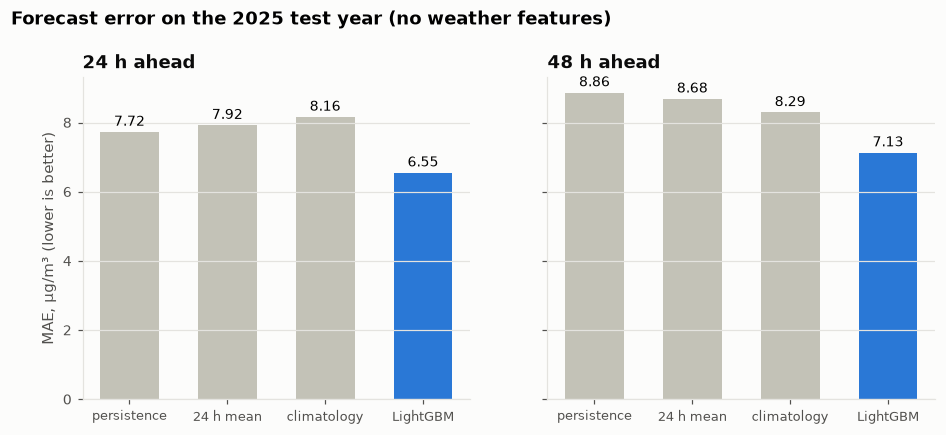

In [3]:
names = [n for n in runs if n.endswith("noweather")]
models = ["persistence", "mean_24h", "climatology", "lightgbm"]
fig, axes = plt.subplots(1, len(names), figsize=(10, 3.8), sharey=True)
for ax, name in zip(np.atleast_1d(axes), names, strict=True):
    t = test_table(name).loc[models]
    colors = ["#c3c2b7"] * 3 + [SERIES[0]]
    bars = ax.bar(range(len(models)), t["mae"], color=colors, width=0.6)
    ax.bar_label(bars, fmt="%.2f", fontsize=9, padding=2)
    ax.set_xticks(range(len(models)), ["persistence", "24 h mean", "climatology", "LightGBM"],
                  fontsize=8.5)
    ax.set_title(f"{runs[name]['horizon_hours']} h ahead")
np.atleast_1d(axes)[0].set_ylabel("MAE, µg/m³ (lower is better)")
fig.suptitle("Forecast error on the 2025 test year (no weather features)",
             x=0.06, y=1.04, ha="left", fontweight="bold")
save(fig, "forecast_mae_by_model")

LightGBM beats every baseline at both horizons, and its advantage over persistence
grows with the horizon (persistence decays faster than the model). At 48 h even
climatology beats persistence: two days out, the seasonal average tells you more
than the current reading.

## 2. Where the errors are: season and pollution level

WindowsPath('D:/airquality/reports/figures/forecast_mae_by_month.png')

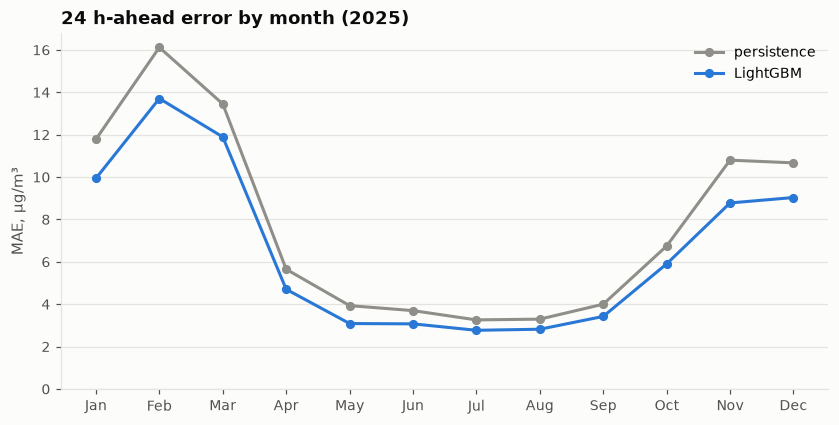

In [4]:
name = "h24_noweather"
pred = pd.read_parquet(MODELS / f"test_predictions_{name}.parquet")
by_month = pred.assign(
    err_lgb=(pred.lightgbm - pred.target).abs(),
    err_per=(pred.persistence - pred.target).abs(),
).groupby("month")[["err_lgb", "err_per"]].mean()

fig, ax = plt.subplots()
ax.plot(by_month.index, by_month.err_per, color="#8f8e88", marker="o", ms=5, label="persistence")
ax.plot(by_month.index, by_month.err_lgb, color=SERIES[0], marker="o", ms=5, label="LightGBM")
ax.set_xticks(range(1, 13), ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
                             "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.set(ylabel="MAE, µg/m³", ylim=(0, None), title="24 h-ahead error by month (2025)")
ax.legend()
save(fig, "forecast_mae_by_month")

In [5]:
bins = [0, 10, 20, 35, 50, 75, 1000]
labels = ["0–10", "10–20", "20–35", "35–50", "50–75", ">75"]
lvl = pred.assign(level=pd.cut(pred.target, bins, labels=labels, right=False))
by_level = lvl.groupby("level", observed=True).apply(
    lambda g: pd.Series({"hours": len(g), "mean_error_lgb": (g.lightgbm - g.target).mean(),
                         "mae_lgb": (g.lightgbm - g.target).abs().mean(),
                         "mae_persistence": (g.persistence - g.target).abs().mean()}),
    include_groups=False)
by_level.round(2)

,hours,mean_error_lgb,mae_lgb,mae_persistence
level,,,,
0–10,352663.0,3.12,3.70,4.22
10–20,239831.0,0.12,4.57,6.87
20–35,112613.0,-5.64,8.30,11.32
35–50,37185.0,-15.42,16.13,16.96
50–75,19521.0,-29.49,29.57,25.42
>75,7907.0,-66.47,66.47,51.70


Errors are largest in winter, when levels and variability are highest, and LightGBM
beats persistence in every month. The table by pollution level shows the main
weakness:
- Below 35 µg/m³ (most hours) LightGBM is much better than persistence.
- **Above 50 µg/m³ it is worse than persistence** and strongly under-predicts
  (mean error about −30 µg/m³ at 50–75 and −66 µg/m³ above 75).

A model trained to minimise average error learns to hedge toward typical values a
day ahead. That's why episodes get their own classifier (section 4), and why weather
features, which can signal an incoming inversion, matter.

## 3. A winter episode, hour by hour

WindowsPath('D:/airquality/reports/figures/forecast_episode.png')

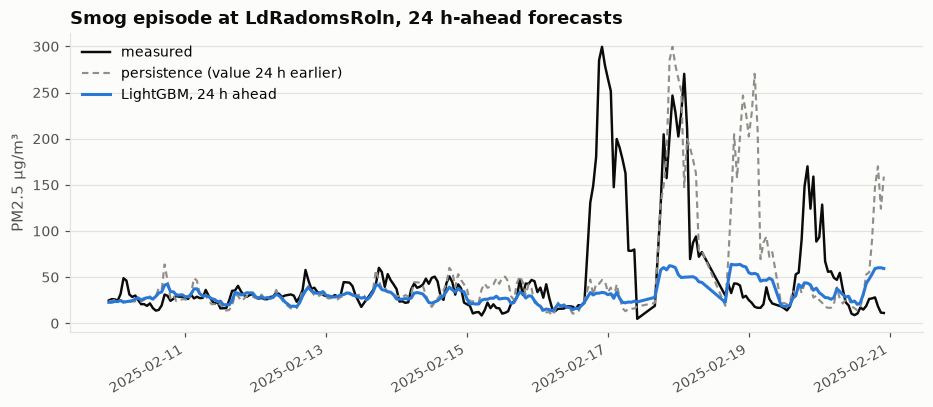

In [6]:
winter = pred[(pred.target_ts >= "2025-01-01") & (pred.target_ts < "2025-03-01")
              & ~pred.station_code.astype(str).str.endswith("MOB")]  # fixed stations only
station = winter.groupby("station_code", observed=True).target.max().idxmax()
peak = winter[winter.station_code == station].sort_values("target").iloc[-1].target_ts
window = pred[(pred.station_code == station)
              & (pred.target_ts >= peak - pd.Timedelta(days=7))
              & (pred.target_ts <= peak + pd.Timedelta(days=4))].sort_values("target_ts")

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(window.target_ts, window.target, color="#0b0b0b", lw=1.6, label="measured")
ax.plot(window.target_ts, window.persistence, color="#8f8e88", lw=1.4, ls=(0, (3, 2)),
        label="persistence (value 24 h earlier)")
ax.plot(window.target_ts, window.lightgbm, color=SERIES[0], lw=2, label="LightGBM, 24 h ahead")
ax.set(ylabel="PM2.5 µg/m³", title=f"Smog episode at {station}, 24 h-ahead forecasts")
ax.legend(loc="upper left")
fig.autofmt_xdate()
save(fig, "forecast_episode")

Persistence is simply the measured curve shifted by a day, so it is always late:
it misses an episode's first day and then predicts a peak after it has passed.
LightGBM follows the general level and daily cycle, but **it does not see the peaks
coming**: from pollution history alone, nothing says that tomorrow brings a calm,
cold inversion. That is the job of the weather features.

## 4. High-pollution early warning (> 50 µg/m³)

In [7]:
rows = []
for name in runs:
    r, h = runs[name], runs[name]["horizon_hours"]
    t = test_table(name)
    clf = r["episode_classifier"]["test"]
    rows += [
        {"experiment": name, "method": "persistence rule (now > 50)",
         "precision": t.loc["persistence", "episode_precision"],
         "recall": t.loc["persistence", "episode_recall"], "f1": t.loc["persistence", "episode_f1"]},
        {"experiment": name, "method": "LightGBM point forecast > 50",
         "precision": t.loc["lightgbm", "episode_precision"],
         "recall": t.loc["lightgbm", "episode_recall"], "f1": t.loc["lightgbm", "episode_f1"]},
        {"experiment": name, "method": f"episode classifier (p ≥ {clf['cutoff']:.2f})",
         "precision": clf["precision"], "recall": clf["recall"], "f1": clf["f1"],
         "pr_auc": clf["pr_auc"], "roc_auc": clf["roc_auc"]},
    ]
episodes = pd.DataFrame(rows).set_index(["experiment", "method"])
print(f"high-pollution hours in the 2025 test set: "
      f"{runs['h24_noweather']['episode_classifier']['test']['positives']:,}")
episodes.round(3)

high-pollution hours in the 2025 test set: 27,265


precision  recall     f1  pr_auc  \
experiment    method                                                            
h24_noweather persistence rule (now > 50)        0.348   0.348  0.348     NaN   
              LightGBM point forecast > 50       0.604   0.058  0.107     NaN   
              episode classifier (p ≥ 0.21)      0.330   0.500  0.398   0.343   
h48_noweather persistence rule (now > 50)        0.260   0.260  0.260     NaN   
              LightGBM point forecast > 50       0.660   0.016  0.032     NaN   
              episode classifier (p ≥ 0.16)      0.247   0.508  0.332   0.277   

                                             roc_auc  
experiment    method                                  
h24_noweather persistence rule (now > 50)        NaN  
              LightGBM point forecast > 50       NaN  
              episode classifier (p ≥ 0.21)    0.928  
h48_noweather persistence rule (now > 50)        NaN  
              LightGBM point forecast > 50       NaN  
              episode classifier (p ≥ 0.16)    0.911

The point forecast rarely crosses 50 µg/m³ (recall 6 % at 24 h). The dedicated
classifier, with its alert cut-off chosen on 2024 data, beats the simple "it's bad
now, so it'll be bad tomorrow" rule at both horizons (F1 0.40 vs 0.35 at 24 h,
0.33 vs 0.26 at 48 h). It catches about half of all high-pollution hours, and
ranks hours by risk well (ROC-AUC above 0.9).

Caveat: 2025 had almost twice as many high-pollution hours as 2024 (27k vs 14k).
The cut-off was tuned on the calmer year, so results depend on how smoggy a year is.

## 5. What the model relies on

WindowsPath('D:/airquality/reports/figures/forecast_feature_importance.png')

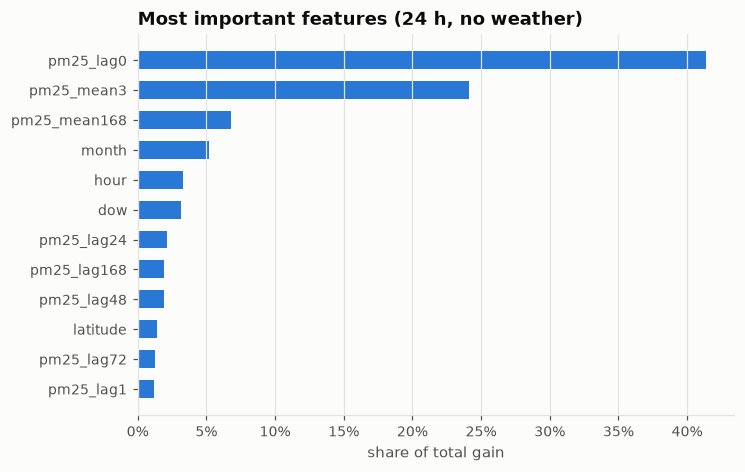

In [8]:
name = "h24_noweather"
booster = lgb.Booster(model_file=str(MODELS / f"lgbm_{name}.txt"))
gain = pd.Series(booster.feature_importance("gain"), index=booster.feature_name())
gain = (gain / gain.sum()).sort_values().tail(12)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(gain.index, gain.values, color=SERIES[0], height=0.6)
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
ax.set(xlabel="share of total gain", title="Most important features (24 h, no weather)")
save(fig, "forecast_feature_importance")

The current level and short-term averages dominate, followed by the weekly mean
(the station's recent baseline) and the target hour. Location features let one
global model learn regional differences.

### Caveats
- **Weather variant:** in training and testing, the target hour's weather comes from
  ERA5 reanalysis, i.e. a *perfect* weather forecast. Real forecasts are less
  accurate, so the weather model's scores are an optimistic upper bound. The gap
  between the no-weather model (a realistic lower bound) and the weather model shows
  how much a good weather forecast is worth.
- Mobile stations and stations that joined the network recently have little history.
- One global model for all stations. Per-region models or station-level tuning
  could help but would add complexity.